# Flight Ticket Price Prediction

**Task:** predict `price` for every row in `test.csv` using what the training data shows about airlines, routes, timings, seat class and booking window. Price is a continuous number, so this is a **regression** problem.

**Notebook outline**

1. First look at the data and its data types
2. Data quality: missing values, damaged flight codes, duplicates, outliers
3. Exploratory data analysis
4. Cleaning and feature engineering
5. Preprocessing for each family of model
6. How models are validated
7. Model comparison
8. How much the cleaning and target choices mattered
9. Hyperparameter tuning on four models
10. Where the final model goes wrong
11. What drives the price
12. Training the final model and writing `submission.csv`
13. Conclusions

In [3]:
import glob
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

SEED = 42
ECONOMY, BUSINESS = '#2a78d6', '#eb6834'
CLASS_COLOURS = {'Economy': ECONOMY, 'Business': BUSINESS}

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})

In [4]:
def find_file(name):
    '''Finds a competition file on Kaggle, or next to the notebook when run elsewhere.'''
    matches = glob.glob(f'/kaggle/input/**/{name}', recursive=True)
    return matches[0] if matches else name

train = pd.read_csv(find_file('train.csv'))
test = pd.read_csv(find_file('test.csv'))
print('train:', train.shape)
print('test: ', test.shape)

train: (40000, 12)
test:  (10000, 11)


## 1. First look at the data

In [5]:
train.head()

,id,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           40000 non-null  int64  
 1   airline      35387 non-null  object 
 2   flight       40000 non-null  object 
 3   source       40000 non-null  object 
 4   departure    35208 non-null  object 
 5   stops        37681 non-null  object 
 6   arrival      40000 non-null  object 
 7   destination  40000 non-null  object 
 8   class        40000 non-null  object 
 9   duration     36987 non-null  float64
 10  days_left    35562 non-null  float64
 11  price        40000 non-null  int64  
dtypes: float64(2), int64(2), object(8)
memory usage: 3.7+ MB


**Data types.** The training data has 40,000 rows and 12 columns: one row identifier, 10 features and the target. `test.csv` has 10,000 rows and the same columns without `price`.

| Type | Columns |
|---|---|
| Numerical | `duration` (float), `days_left` (float), `price` (integer, the target) |
| Categorical | `airline`, `flight`, `source`, `departure`, `stops`, `arrival`, `destination`, `class` (text) |
| Identifier | `id` (integer, a row number and not a real feature) |

Three things to note:

- `days_left` is really a whole number. It is stored as a float because it has missing values.
- `stops`, `departure` and `arrival` are text but have a natural order.
- `flight` has hundreds of distinct values, so it needs different handling from the other categories.

The table below states the data type of every column explicitly.

In [7]:
data_type_of = {
    'id': 'Identifier (integer)',
    'airline': 'Categorical, nominal',
    'flight': 'Categorical, nominal (800+ codes)',
    'source': 'Categorical, nominal',
    'departure': 'Categorical, ordinal (time of day)',
    'stops': 'Categorical, ordinal (zero < one < two_or_more)',
    'arrival': 'Categorical, ordinal (time of day)',
    'destination': 'Categorical, nominal',
    'class': 'Categorical, binary',
    'duration': 'Numerical, continuous (hours)',
    'days_left': 'Numerical, discrete (days)',
    'price': 'Numerical, continuous (target)',
}
pd.DataFrame({
    'stored as (pandas dtype)': train.dtypes.astype(str),
    'data type': pd.Series(data_type_of),
    'distinct values': train.nunique(),
    'in test.csv': [col in test.columns for col in train.columns],
})

,stored as (pandas dtype),data type,distinct values,in test.csv
id,int64,Identifier (integer),40000,True
airline,object,"Categorical, nominal",6,True
flight,object,"Categorical, nominal (800+ codes)",869,True
source,object,"Categorical, nominal",6,True
departure,object,"Categorical, ordinal (time of day)",6,True
stops,object,"Categorical, ordinal (zero < one < two_or_more)",3,True
arrival,object,"Categorical, ordinal (time of day)",6,True
destination,object,"Categorical, nominal",6,True
class,object,"Categorical, binary",2,True
duration,float64,"Numerical, continuous (hours)",416,True


### Descriptive statistics of the numerical columns

The minimum, maximum, mean and median of each numerical column, with the standard deviation and skewness for context.

In [8]:
numerical_cols = ['duration', 'days_left', 'price']

def describe_numbers(df, cols):
    summary = df[cols].agg(['count', 'min', 'max', 'mean', 'median', 'std']).T
    summary['skewness'] = df[cols].skew()
    return summary.round(2)

print('Training data')
display(describe_numbers(train, numerical_cols))
print('Test data (no price column)')
display(describe_numbers(test, ['duration', 'days_left']))

Training data


,count,min,max,mean,median,std,skewness
duration,36987.0,0.83,47.08,12.00,11.08,7.11,0.61
days_left,35562.0,1.00,49.00,26.20,26.00,13.47,-0.05
price,40000.0,1105.00,114704.00,20801.49,7353.00,22729.15,1.06


Test data (no price column)


,count,min,max,mean,median,std,skewness
duration,9418.0,0.92,40.42,12.01,11.17,7.09,0.61
days_left,9304.0,1.00,49.00,26.16,26.00,13.45,-0.04


**What the statistics show**

- **price** runs from 1,105 to 114,704. Its mean (about 20,800) is nearly three times its median (7,353), so a small number of expensive tickets pull the average up. Section 3 shows these are Business class fares.
- **duration** runs from about 0.8 to 47 hours, with mean and median both near 11 to 12 hours.
- **days_left** runs from 1 to 49 days, with mean and median both about 26, so bookings are spread evenly across the window.
- Test has very similar ranges and averages to train, so the model is predicting on familiar ground.

In [9]:
categorical_cols = ['airline', 'flight', 'source', 'departure', 'stops', 'arrival', 'destination', 'class']
pd.DataFrame({
    'distinct values': train[categorical_cols].nunique(),
    'most common value': train[categorical_cols].mode().iloc[0],
})

,distinct values,most common value
airline,6,Vistara
flight,869,0.00E+00
source,6,Delhi
departure,6,Morning
stops,3,one
arrival,6,Night
destination,6,Mumbai
class,2,Economy


## 2. Data quality

### 2.1 Missing values

,train missing,train %,test missing,test %
stops,2319,5.8,651.0,6.5
duration,3013,7.5,582.0,5.8
days_left,4438,11.1,696.0,7.0
airline,4613,11.5,548.0,5.5
departure,4792,12.0,920.0,9.2


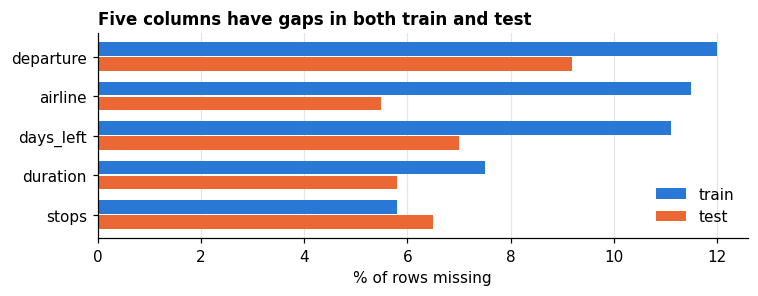

In [10]:
missing = pd.DataFrame({
    'train missing': train.isna().sum(),
    'train %': (train.isna().mean() * 100).round(1),
    'test missing': test.isna().sum(),
    'test %': (test.isna().mean() * 100).round(1),
}).drop(index=['id', 'price'])
missing = missing[missing['train missing'] > 0].sort_values('train %')
display(missing)

fig, ax = plt.subplots(figsize=(7, 2.8))
rows = np.arange(len(missing))
ax.barh(rows + 0.19, missing['train %'], height=0.34, color=ECONOMY, label='train')
ax.barh(rows - 0.19, missing['test %'], height=0.34, color=BUSINESS, label='test')
ax.set_yticks(rows, missing.index)
ax.set_xlabel('% of rows missing')
ax.set_title('Five columns have gaps in both train and test')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Five features have gaps of roughly 6 to 12% in train. Test has gaps as well, and a prediction is needed for every test row, so dropping rows is not an option. The gaps have to be filled sensibly.

### 2.2 A hidden problem in the `flight` column

`flight` shows no missing values, but it should look like `UK-706`. Some rows contain something else.

In [11]:
normal_code = train['flight'].str.match(r'^[A-Z0-9]{2}-\d+$')
print(f'Rows with a normal flight code:  {normal_code.sum():,}')
print(f'Rows with a damaged flight code: {(~normal_code).sum():,}\n')
print(train.loc[~normal_code, 'flight'].value_counts().head(6).to_string())

exponents = train['flight'].str.extract(r'^6\.00E-(\d+)$')[0].dropna().astype(int)
print(f'\nLargest exponent in a 6.00E code: {exponents.max()}\n')

code_prefix = train['flight'].str[:2].where(normal_code, 'damaged')
pd.crosstab(code_prefix, train['airline'].fillna('(missing)'))

Rows with a normal flight code:  34,078
Rows with a damaged flight code: 5,922

flight
0.00E+00     5240
6.00E-269      40
6.00E-179      34
0.00E-02       30
6.00E-157      27
6.00E-139      26

Largest exponent in a 6.00E code: 308



airline,(missing),AirAsia,Air_India,GO_FIRST,Indigo,SpiceJet,Vistara
flight,,,,,,,
AI,1203,0,9222,0,0,0,0
G8,364,0,0,2805,0,0,0
I5,247,1958,0,0,0,0,0
SG,144,0,0,0,0,1103,0
UK,1969,0,0,0,0,0,15063
damaged,686,0,0,0,5236,0,0


This table shows two useful things.

**Every damaged code belongs to Indigo.** Indigo's real flight codes start with `6E`, for example `6E-269`. A spreadsheet reads that as the number 6 × 10⁻²⁶⁹ and rewrites it as `6.00E-269`. Exponents only survive up to 308, which is where a standard floating point number runs out of range. Anything smaller becomes `0.00E+00`. The damaged codes in this data stop at exactly `6.00E-308`, which fits this explanation.

**Every airline can be recovered.** Each code prefix belongs to one airline: `UK` is Vistara, `AI` is Air India, `G8` is GO FIRST, `I5` is AirAsia, `SG` is SpiceJet, and a damaged code means Indigo. So all 4,613 missing airlines in train can be filled exactly, with no guessing.

The repair below restores `6.00E-269` to `6E-269`. Where the number is gone, the code becomes `6E-unknown`.

In [12]:
CODE_TO_AIRLINE = {'UK': 'Vistara', 'AI': 'Air_India', '6E': 'Indigo',
                   'G8': 'GO_FIRST', 'I5': 'AirAsia', 'SG': 'SpiceJet'}

def repair_flight_codes(df):
    df = df.copy()
    flight = df['flight'].astype(str)
    is_normal = flight.str.match(r'^[A-Z0-9]{2}-\d+$')
    number_kept = flight.str.extract(r'^6\.00E-(\d+)$')[0]
    df['flight'] = flight.where(is_normal, '6E-' + number_kept.fillna('unknown'))
    df['airline'] = df['airline'].fillna(df['flight'].str[:2].map(CODE_TO_AIRLINE))
    df['flight_num'] = pd.to_numeric(df['flight'].str.split('-').str[1], errors='coerce')
    return df

repaired = repair_flight_codes(train)
print('Missing airlines before:', train['airline'].isna().sum())
print('Missing airlines after: ', repaired['airline'].isna().sum())
print('Missing airlines in test after:', repair_flight_codes(test)['airline'].isna().sum())
print('Rows where a known airline changed:', (train['airline'].notna() & (train['airline'] != repaired['airline'])).sum())

Missing airlines before: 4613
Missing airlines after:  0
Missing airlines in test after: 0
Rows where a known airline changed: 0


### 2.3 Duplicates and the `id` column

In [13]:
feature_cols = [c for c in train.columns if c not in ('id', 'price')]

print('Exact duplicate rows, ignoring id:', train.duplicated(subset=feature_cols + ['price']).sum())
print('Correlation between id and price:', round(train['id'].corr(train['price']), 4))

train = train.drop_duplicates(subset=feature_cols + ['price']).reset_index(drop=True)
print('Training rows after removing duplicates:', len(train))

Exact duplicate rows, ignoring id: 250
Correlation between id and price: -0.0026
Training rows after removing duplicates: 39750


Exact copies are removed. If a copy landed in both the training and validation parts of a split, the model would be tested on a row it had already seen, and the score would look better than it should.

`id` has essentially no relationship with price, so it is dropped as a feature. It is only used to label the submission.

### 2.4 Outliers

Price outliers across all rows: 14
class
Business     515
Economy     1929

Duration above 40 hours: 7
Non-positive prices: 0


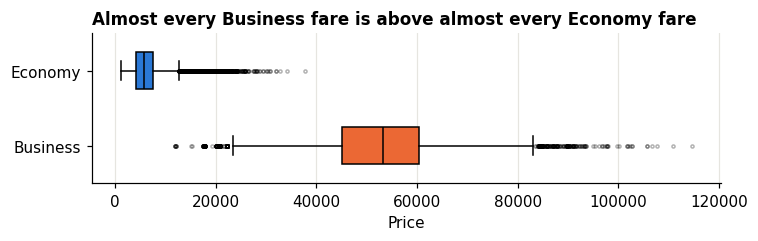

In [14]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    return ((series < q1 - fence) | (series > q3 + fence)).sum()

print('Price outliers across all rows:', iqr_outliers(train['price']))
print(train.groupby('class')['price'].apply(iqr_outliers).rename('Price outliers within class').to_string())
print('\nDuration above 40 hours:', (train['duration'] > 40).sum())
print('Non-positive prices:', (train['price'] <= 0).sum())

fig, ax = plt.subplots(figsize=(7, 2.3))
parts = ax.boxplot([train.loc[train['class'] == c, 'price'] for c in ['Business', 'Economy']],
                   vert=False, widths=0.5, patch_artist=True, flierprops={'markersize': 2, 'alpha': 0.3},
                   medianprops={'color': 'black'})
for box, colour in zip(parts['boxes'], [BUSINESS, ECONOMY]):
    box.set_facecolor(colour)
ax.set_yticks([1, 2], ['Business', 'Economy'])
ax.set_xlabel('Price')
ax.set_title('Almost every Business fare is above almost every Economy fare')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Across the whole dataset only a handful of prices count as outliers. Within each class there are more, but those are plausible fares such as last-minute Economy tickets and premium Business routes, not data errors. Those same kinds of fares will appear in test, so **outliers are kept**. All prices and durations are in a believable range.

## 3. Exploratory data analysis

EDA uses the repaired training data so that airline comparisons include every row.

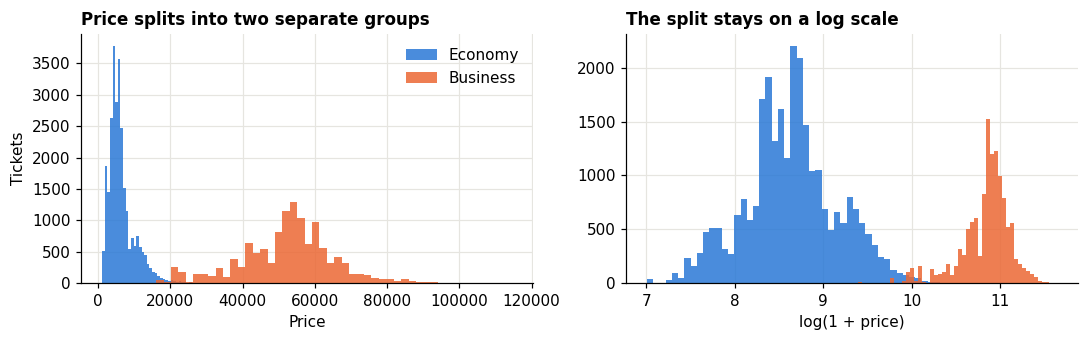

            count     mean      std      min      25%      50%      75%       max
class                                                                            
Business  12331.0  52533.0  13001.0  12000.0  45185.0  53209.0  60365.0  114704.0
Economy   27419.0   6460.0   3668.0   1105.0   4111.0   5660.0   7575.0   37646.0

Skewness of price: 1.07


In [15]:
eda = repair_flight_codes(train)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for cls, colour in CLASS_COLOURS.items():
    prices = eda.loc[eda['class'] == cls, 'price']
    axes[0].hist(prices, bins=50, color=colour, alpha=0.85, label=cls)
    axes[1].hist(np.log1p(prices), bins=50, color=colour, alpha=0.85, label=cls)
axes[0].set(title='Price splits into two separate groups', xlabel='Price', ylabel='Tickets')
axes[1].set(title='The split stays on a log scale', xlabel='log(1 + price)')
axes[0].legend()
plt.tight_layout()
plt.show()

print(eda.groupby('class')['price'].describe().round(0).to_string())
print('\nSkewness of price:', round(eda['price'].skew(), 2))

**Insight: `class` is the biggest single factor.** Price is not one bell curve. It is two groups, with a typical Business ticket costing around nine times a typical Economy ticket. This matters later: a model gets a very high overall R² simply by telling the two classes apart, so R² should also be checked inside each class.

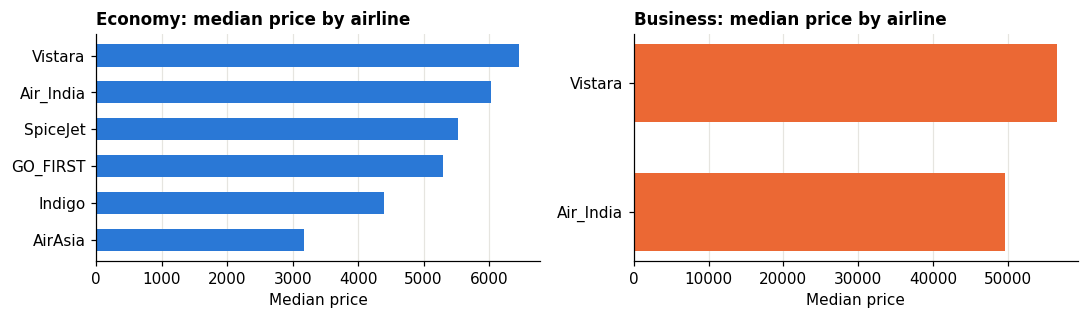

Share of tickets in each class by airline (%):
class      Business  Economy
airline                     
AirAsia         0.0    100.0
Air_India      41.2     58.8
GO_FIRST        0.0    100.0
Indigo          0.0    100.0
SpiceJet        0.0    100.0
Vistara        47.7     52.3


In [16]:
order = eda[eda['class'] == 'Economy'].groupby('airline')['price'].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, cls in zip(axes, ['Economy', 'Business']):
    medians = eda[eda['class'] == cls].groupby('airline')['price'].median().reindex(order).dropna()
    ax.barh(medians.index, medians.values, color=CLASS_COLOURS[cls], height=0.6)
    ax.set_title(f'{cls}: median price by airline')
    ax.set_xlabel('Median price')
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Share of tickets in each class by airline (%):')
print((pd.crosstab(eda['airline'], eda['class'], normalize='index') * 100).round(1).to_string())

**Insight: airlines differ, and only two sell Business.** Vistara and Air India are the only airlines with Business seats in this data. They also charge the most in Economy, while AirAsia is the cheapest.

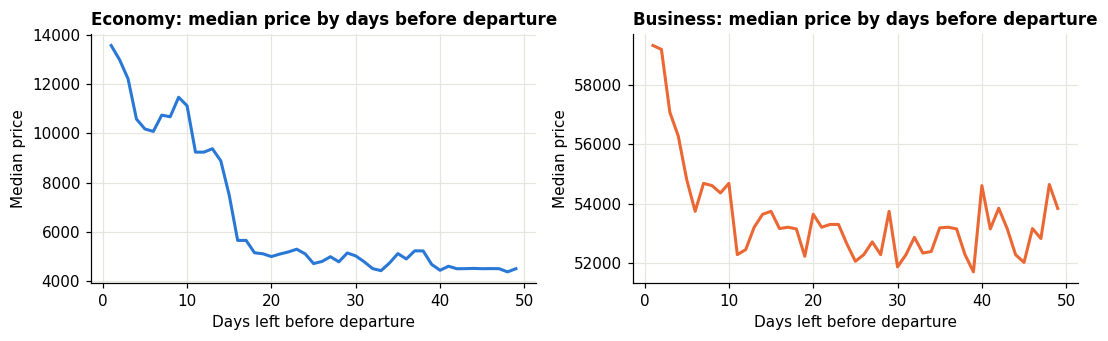

class,Business,Economy
days_left,,
1,59320.0,13582.0
2-3,57790.0,12649.0
4-7,54684.0,10586.0
8-14,53634.0,10008.0
15-21,53164.0,5460.0
22-30,52715.0,5006.0
31-49,53152.0,4658.0


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, cls in zip(axes, ['Economy', 'Business']):
    by_day = eda[eda['class'] == cls].groupby('days_left')['price'].median()
    ax.plot(by_day.index, by_day.values, color=CLASS_COLOURS[cls], linewidth=2)
    ax.set_title(f'{cls}: median price by days before departure')
    ax.set_xlabel('Days left before departure')
    ax.set_ylabel('Median price')
plt.tight_layout()
plt.show()

window = pd.cut(eda['days_left'], [0, 1, 3, 7, 14, 21, 30, 49],
                labels=['1', '2-3', '4-7', '8-14', '15-21', '22-30', '31-49'])
eda.pivot_table(index=window, columns='class', values='price', aggfunc='median', observed=True).round(0)

**Insight: booking window has a sharp step, not a smooth slope.** Median Economy fares sit near 5,000 when booked more than about 16 days ahead, nearly double by 13 days out, and keep climbing into the last few days. Business barely moves until the final days. A straight line cannot capture a step that exists mostly in one class, which is one reason tree models should do better than linear ones here.

class,Business,Economy
stops,,
one,54608.0,5875.0
two_or_more,68743.0,7768.0
zero,27864.0,3428.0


,median duration (hours)
stops,
one,12.08
two_or_more,12.42
zero,2.25


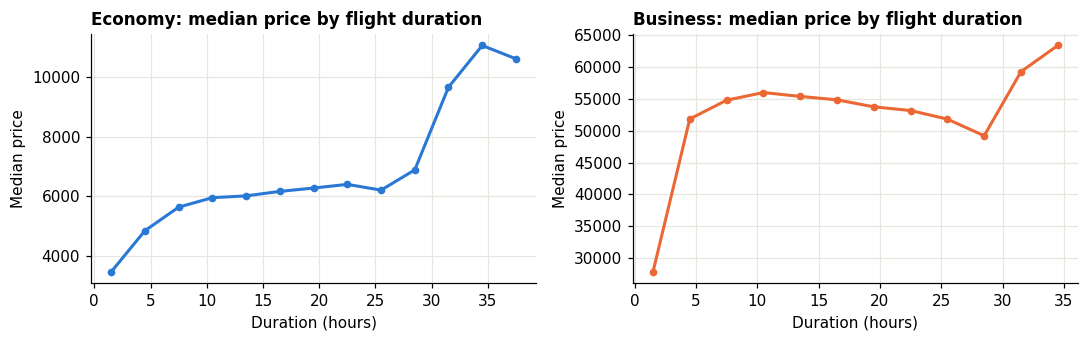

In [18]:
display(eda.pivot_table(index='stops', columns='class', values='price', aggfunc='median').round(0))
display(eda.groupby('stops')['duration'].median().rename('median duration (hours)').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, cls in zip(axes, ['Economy', 'Business']):
    part = eda[eda['class'] == cls].dropna(subset=['duration'])
    by_hours = part.groupby(pd.cut(part['duration'], np.arange(0, 42, 3)), observed=True)['price'].median()
    ax.plot([interval.mid for interval in by_hours.index], by_hours.values, color=CLASS_COLOURS[cls], linewidth=2, marker='o', markersize=4)
    ax.set_title(f'{cls}: median price by flight duration')
    ax.set_xlabel('Duration (hours)')
    ax.set_ylabel('Median price')
plt.tight_layout()
plt.show()

**Insight: direct flights are shortest and cheapest.** Non-stop flights take a little over two hours and cost the least in both classes. Economy prices climb over roughly the first 10 hours of duration and then level off, so the relationship is not a straight line. The rise past 30 hours comes from very few tickets, so it should not be over-read.

,departure median,arrival median
Early_Morning,5596.0,4896.0
Morning,5955.0,5616.0
Afternoon,5618.0,5234.0
Evening,5322.0,6132.0
Night,5441.0,5772.0
Late_Night,4079.0,4366.0


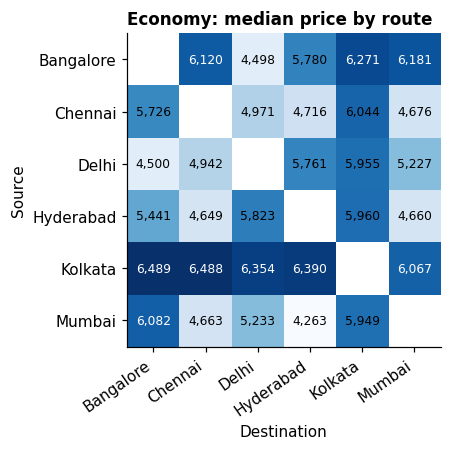

In [19]:
time_order = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']
economy = eda[eda['class'] == 'Economy']

timing = pd.DataFrame({
    'departure median': economy.groupby('departure')['price'].median(),
    'arrival median': economy.groupby('arrival')['price'].median(),
}).reindex(time_order).round(0)
display(timing)

cities = sorted(eda['source'].unique())
route_prices = economy.pivot_table(index='source', columns='destination', values='price', aggfunc='median').reindex(index=cities, columns=cities)

fig, ax = plt.subplots(figsize=(6, 4.2))
image = ax.imshow(route_prices.values, cmap='Blues')
ax.set_xticks(range(len(cities)), cities, rotation=35, ha='right')
ax.set_yticks(range(len(cities)), cities)
ax.grid(False)
for i in range(len(cities)):
    for j in range(len(cities)):
        value = route_prices.values[i, j]
        if not np.isnan(value):
            ax.text(j, i, f'{value:,.0f}', ha='center', va='center', fontsize=8,
                    color='white' if value > np.nanpercentile(route_prices.values, 70) else 'black')
ax.set_xlabel('Destination')
ax.set_ylabel('Source')
ax.set_title('Economy: median price by route')
plt.tight_layout()
plt.show()

**Insight: routes and times still move the price.** Routes out of Kolkata are the most expensive in Economy, at roughly 6,000 to 6,500. The cheapest are Mumbai to Hyderabad and the Delhi and Bangalore pair, at around 4,300 to 4,500. Late-night departures and arrivals are the cheapest time slots, although late-night departures are rare.

In [20]:
print('Correlation with price, all rows:')
print(eda[['duration', 'days_left', 'price']].corr()['price'].round(3).drop('price').to_string())
for cls in ['Economy', 'Business']:
    print(f'\nCorrelation with price, {cls} only:')
    print(eda.loc[eda['class'] == cls, ['duration', 'days_left', 'price']].corr()['price'].round(3).drop('price').to_string())

Correlation with price, all rows:
duration     0.216
days_left   -0.093

Correlation with price, Economy only:
duration     0.295
days_left   -0.553

Correlation with price, Business only:
duration     0.248
days_left   -0.075


**Insight: mixing the classes hides the booking-window effect.** The correlation between `days_left` and price looks weak across all rows and becomes much stronger inside Economy. This again shows the two classes need to be treated as different pricing systems.

## 4. Cleaning and feature engineering

`departure`, `stops` and `duration` have gaps, but flights run on a fixed schedule. The same flight on the same route normally leaves at the same time and has the same stops. So a gap can be filled by looking up what that flight usually does, which is better than filling every gap with one overall value.

The lookup tries the most specific match first and falls back to a broader one:

| Column | First try | Then | Finally |
|---|---|---|---|
| `departure` | same flight and source | same airline and source | most common overall |
| `stops` | same flight and route | same route | most common overall |
| `duration` | same flight, route and stops | same route and stops | median overall |

This is written as a scikit-learn transformer. That means the tables are learned **only from the rows used for training** each time, so validation rows never leak into them.

`days_left` is different. Nothing else in a row tells you when the ticket was booked, so it is not looked up.

`flight_num`, the number after the dash in the flight code, is a new feature. Together with `airline`, it lets a tree isolate individual flights.

In [21]:
def most_common(values):
    modes = values.mode()
    return modes.iloc[0] if len(modes) else np.nan


class FlightCleaner(BaseEstimator, TransformerMixin):
    '''Repairs flight codes and fills schedule gaps from the same flight's usual schedule.'''

    LOOKUPS = {
        'departure': [['flight', 'source'], ['airline', 'source']],
        'stops': [['flight', 'source', 'destination'], ['source', 'destination']],
        'duration': [['flight', 'source', 'destination', 'stops'], ['source', 'destination', 'stops']],
    }

    def fit(self, X, y=None):
        X = repair_flight_codes(X)
        self.tables_, self.overall_ = {}, {}
        for col, levels in self.LOOKUPS.items():
            known = X.dropna(subset=[col])
            summary = 'median' if col == 'duration' else most_common
            self.tables_[col] = [
                (keys, known.groupby(keys)[col].agg(summary).rename(f'{col}_lookup').reset_index())
                for keys in levels
            ]
            self.overall_[col] = known[col].median() if col == 'duration' else most_common(known[col])
        return self

    def transform(self, X):
        X = repair_flight_codes(X)
        for col, levels in self.tables_.items():    # stops is filled before duration uses it
            for keys, table in levels:
                looked_up = X[keys].merge(table, on=keys, how='left')[f'{col}_lookup'].values
                X[col] = X[col].where(X[col].notna(), looked_up)
            X[col] = X[col].fillna(self.overall_[col])
        return X

A lookup is only worth using if it gets the right answer. To test it, known values in a held-out 20% of rows are hidden, then the lookup is compared with the truth.

In [22]:
part_a, part_b = train_test_split(train, test_size=0.2, random_state=SEED)
cleaner_check = FlightCleaner().fit(part_a)

for col in ['departure', 'stops']:
    hidden = part_b.dropna(subset=[col]).reset_index(drop=True)
    truth = hidden[col].copy()
    guess = cleaner_check.transform(hidden.assign(**{col: np.nan}))[col]
    print(f'{col:10s} lookup correct: {(guess == truth).mean():.1%}   always guessing the most common value: {truth.value_counts(normalize=True).iloc[0]:.1%}')

hidden = part_b.dropna(subset=['duration']).reset_index(drop=True)
guess = cleaner_check.transform(hidden.assign(duration=np.nan))['duration']
overall = np.abs(hidden['duration'] - part_a['duration'].median()).mean()
print(f'duration   lookup average error: {np.abs(guess - hidden["duration"]).mean():.2f} hours   always using the median: {overall:.2f} hours')

departure  lookup correct: 90.0%   always guessing the most common value: 23.7%
stops      lookup correct: 94.8%   always guessing the most common value: 83.1%
duration   lookup average error: 2.82 hours   always using the median: 5.76 hours


### Summary: how every missing value is handled

No rows are dropped, because test has the same gaps and every test row needs a prediction.

| Column | Missing in train | How it is handled |
|---|---|---|
| `airline` | 11.5% | Recovered exactly from the flight code (section 2.2) |
| `departure` | 12.0% | Imputed from the same flight's usual departure slot |
| `stops` | 5.8% | Imputed from the same flight's usual number of stops on that route |
| `duration` | 7.5% | Imputed with the median duration of the same flight, route and stops |
| `days_left` | 11.1% | Imputed with the training median for the linear, KNN and tree models. LightGBM and XGBoost handle missing values natively by learning which branch they should follow. |

The check below confirms that after cleaning, only `days_left` still has gaps, and those are handled in the next step.

In [23]:
cleaned_train = FlightCleaner().fit(train).transform(train)
cleaned_test = FlightCleaner().fit(train).transform(test)
pd.DataFrame({
    'train missing before': train[feature_cols].isna().sum(),
    'train missing after cleaning': cleaned_train[feature_cols].isna().sum(),
    'test missing after cleaning': cleaned_test[feature_cols].isna().sum(),
})

,train missing before,train missing after cleaning,test missing after cleaning
airline,4609,0,0
flight,0,0,0
source,0,0,0
departure,4788,0,0
stops,2319,0,0
arrival,0,0,0
destination,0,0,0
class,0,0,0
duration,3005,0,0
days_left,4195,4195,696


## 5. Preprocessing for each family of model

Different models need different inputs, so there are three paths. All three start with `FlightCleaner`.

| Models | Categories | Numbers | Why |
|---|---|---|---|
| Linear, Ridge, KNN | One-hot encoded | Median-filled, then scaled | These models use distances or weights, so categories cannot be treated as ordered numbers, and scale matters |
| Decision Tree, Random Forest, Histogram Boosting | Ordinal encoded | Median-filled | Trees only ask "is this value above a threshold?", so scaling makes no difference |
| LightGBM, XGBoost | Native `category` type | Left as they are | These libraries handle categories and missing values internally, which suits the 800+ flight codes |

`flight` is left out of the one-hot path, because it would add over 800 sparse columns for these simpler models.

**Scaling decision.** `duration` and `days_left` are on very different scales (hours versus days), so they are standardised to mean 0 and standard deviation 1 for Linear Regression, Ridge and KNN. KNN measures distance between rows and Ridge penalises coefficient size, so both would otherwise be dominated by whichever feature has the bigger numbers. Tree-based models are **not** scaled, because a split such as "duration > 5 hours" works the same at any scale.

**Encoding decision.** The categorical columns have no numeric meaning, so they must be encoded. One-hot encoding gives each category its own 0/1 column, which is needed for linear models and KNN. Ordinal encoding turns each category into a single integer, which trees can split on. LightGBM and XGBoost read the categories directly. The target `price` is not scaled or transformed, and section 8 shows why.

In [24]:
base_categories = ['airline', 'source', 'departure', 'stops', 'arrival', 'destination', 'class']
number_cols = ['duration', 'days_left', 'flight_num']


class ToCategory(BaseEstimator, TransformerMixin):
    '''Gives LightGBM and XGBoost pandas category columns, using only levels seen in training.'''

    def __init__(self, categories=None, numbers=None):
        self.categories = categories
        self.numbers = numbers

    def fit(self, X, y=None):
        self.levels_ = {col: pd.Index(sorted(X[col].dropna().unique())) for col in self.categories}
        return self

    def transform(self, X):
        X = X[self.categories + self.numbers].copy()
        for col in self.categories:
            X[col] = pd.Categorical(X[col], categories=self.levels_[col])
        return X


one_hot_path = ColumnTransformer([
    ('numbers', Pipeline([('fill', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), ['duration', 'days_left']),
    ('categories', OneHotEncoder(handle_unknown='ignore'), base_categories),
])

ordinal_path = ColumnTransformer([
    ('numbers', SimpleImputer(strategy='median'), number_cols),
    ('categories', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), base_categories),
])

category_path = ToCategory(categories=base_categories + ['flight'], numbers=number_cols)


def linear_pipeline(model):
    return Pipeline([('clean', FlightCleaner()), ('prepare', one_hot_path), ('model', model)])

def tree_pipeline(model):
    return Pipeline([('clean', FlightCleaner()), ('prepare', ordinal_path), ('model', model)])

def boosting_pipeline(model):
    return Pipeline([('clean', FlightCleaner()), ('prepare', category_path), ('model', model)])


X = train[feature_cols]
y = train['price'].values
X_test = test[feature_cols]

## 6. How models are validated

**5-fold cross-validation.** The training data is split into five parts. Each model trains on four and predicts the fifth, five times over, so every row gets a prediction from a model that never saw it. These are called out-of-fold predictions.

The full pipeline, including `FlightCleaner`, is refitted in every fold. That keeps validation rows out of every step, so the score is a fair estimate of performance on new data.

**Scores:**

- **R²** is the share of price variation the model explains. 1 is perfect and 0 is no better than always predicting the average. This is the main score used to compare models.
- **RMSE** is a typical error in the same units as price, with large mistakes counted more heavily.
- **MAE** is the average size of the error, also in price units.

In [25]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

results, out_of_fold = [], {}

def evaluate(name, model, features=None, target=None, store=True):
    features = X if features is None else features
    target = y if target is None else target
    start = time.time()
    predictions = cross_val_predict(model, features, target, cv=cv)
    row = {
        'model': name,
        'R2': r2_score(target, predictions),
        'RMSE': np.sqrt(mean_squared_error(target, predictions)),
        'MAE': mean_absolute_error(target, predictions),
        'seconds': round(time.time() - start),
    }
    if store:
        results.append(row)
        out_of_fold[name] = predictions
    print(f"{name:28s} R2 {row['R2']:.4f}   RMSE {row['RMSE']:>8,.0f}   MAE {row['MAE']:>8,.0f}   {row['seconds']}s")
    return row

## 7. Model comparison

**Eight different types of model** are trained: Linear Regression, Ridge Regression, K-Nearest Neighbours, Decision Tree, Random Forest, Histogram Gradient Boosting, XGBoost and LightGBM. They run from simplest to most flexible.

A mean-price baseline comes first. It always predicts the average price, the same as the sample submission, and sets the floor that every real model has to beat.

Every score is measured on validation folds the model did not train on, so the models are compared fairly.

In [26]:
simple_models = [
    ('Mean price (baseline)', linear_pipeline(DummyRegressor())),
    ('Linear Regression', linear_pipeline(LinearRegression())),
    ('Ridge Regression', linear_pipeline(Ridge(alpha=1.0))),
    ('K-Nearest Neighbours', linear_pipeline(KNeighborsRegressor(n_neighbors=10, weights='distance'))),
    ('Decision Tree', tree_pipeline(DecisionTreeRegressor(min_samples_leaf=5, random_state=SEED))),
    ('Random Forest', tree_pipeline(RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=SEED))),
    ('Histogram Boosting', tree_pipeline(HistGradientBoostingRegressor(max_iter=500, learning_rate=0.06, max_leaf_nodes=63, random_state=SEED))),
]
for name, model in simple_models:
    evaluate(name, model)

Mean price (baseline)        R2 -0.0001   RMSE   22,715   MAE   19,758   5s
Linear Regression            R2 0.9110   RMSE    6,775   MAE    4,584   5s
Ridge Regression             R2 0.9110   RMSE    6,775   MAE    4,584   5s
K-Nearest Neighbours         R2 0.9540   RMSE    4,873   MAE    2,870   61s
Decision Tree                R2 0.9730   RMSE    3,735   MAE    1,883   6s
Random Forest                R2 0.9803   RMSE    3,192   MAE    1,667   29s
Histogram Boosting           R2 0.9794   RMSE    3,257   MAE    1,838   21s


XGBoost                      R2 0.9828   RMSE    2,976   MAE    1,585   75s
LightGBM                     R2 0.9827   RMSE    2,990   MAE    1,639   34s


,R2,RMSE,MAE,seconds
model,,,,
Mean price (baseline),-0.0001,22715.0,19758.0,5
Linear Regression,0.9110,6775.0,4584.0,5
Ridge Regression,0.9110,6775.0,4584.0,5
K-Nearest Neighbours,0.9540,4873.0,2870.0,61
Decision Tree,0.9730,3735.0,1883.0,6
Histogram Boosting,0.9794,3257.0,1838.0,21
Random Forest,0.9803,3192.0,1667.0,29
LightGBM,0.9827,2990.0,1639.0,34
XGBoost,0.9828,2976.0,1585.0,75


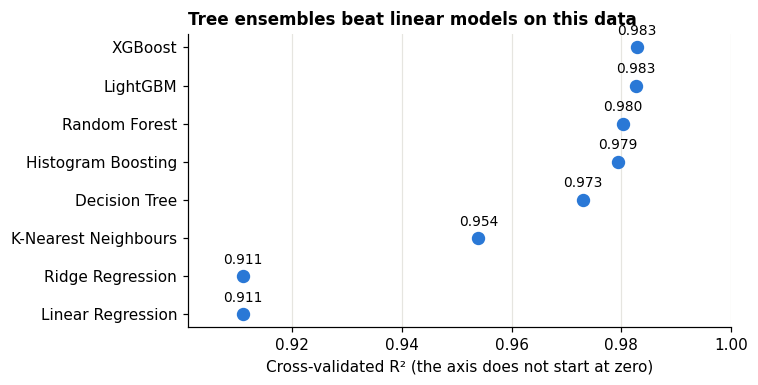

In [27]:
XGB_PARAMS = dict(n_estimators=800, learning_rate=0.05, max_depth=9, min_child_weight=3,
                  subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, max_cat_to_onehot=8,
                  tree_method='hist', enable_categorical=True, n_jobs=-1, random_state=SEED)

LGBM_PARAMS = dict(n_estimators=800, learning_rate=0.05, num_leaves=127, min_child_samples=10,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                   cat_smooth=10, cat_l2=5, min_data_per_group=20, max_cat_to_onehot=4,
                   n_jobs=-1, verbosity=-1, random_state=SEED)

evaluate('XGBoost', boosting_pipeline(XGBRegressor(**XGB_PARAMS)))
evaluate('LightGBM', boosting_pipeline(LGBMRegressor(**LGBM_PARAMS)))

comparison = pd.DataFrame(results).set_index('model').sort_values('R2')
display(comparison.round({'R2': 4, 'RMSE': 0, 'MAE': 0}))

fig, ax = plt.subplots(figsize=(7, 3.6))
shown = comparison.drop(index='Mean price (baseline)')
ax.scatter(shown['R2'], shown.index, s=60, color=ECONOMY, zorder=3)
for position, value in enumerate(shown['R2']):
    ax.annotate(f'{value:.3f}', (value, position), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9)
ax.set_xlim(shown['R2'].min() - 0.01, 1.0)
ax.set_xlabel('Cross-validated R² (the axis does not start at zero)')
ax.set_title('Tree ensembles beat linear models on this data')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**What the comparison shows**

- The baseline scores an R² of about 0, as expected for a constant guess.
- Linear and Ridge Regression score about 0.91 and are the weakest real models. They add a fixed amount for each feature, while here the effect of a feature depends on the others. The booking-window step, for example, mostly exists in Economy. Ridge matches plain Linear Regression because there are many rows and few columns, so there is little overfitting for it to correct.
- KNN reaches about 0.95 by comparing similar tickets, even without the flight code.
- A single Decision Tree scores about 0.97, which confirms the patterns are non-linear. Random Forest and boosting combine many trees and improve on it further.
- XGBoost and LightGBM are the strongest at about 0.98, and their RMSE is around 7% lower than Random Forest's. They are effectively tied.

LightGBM is chosen for tuning because it matches XGBoost in about half the time.

## 8. How much the cleaning and target choices mattered

Each step below changes one thing and keeps the same LightGBM settings, so the difference comes from that change alone.

In [28]:
class RawColumns(BaseEstimator, TransformerMixin):
    '''Skips all cleaning, for comparison only.'''
    def __init__(self, categories=None):
        self.categories = categories
    def fit(self, X, y=None):
        self.levels_ = {col: pd.Index(sorted(X[col].dropna().unique())) for col in self.categories}
        return self
    def transform(self, X):
        X = X[self.categories + ['duration', 'days_left']].copy()
        for col in self.categories:
            X[col] = pd.Categorical(X[col], categories=self.levels_[col])
        return X


class RepairOnly(BaseEstimator, TransformerMixin):
    '''Repairs flight codes but leaves schedule gaps unfilled, for comparison only.'''
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return repair_flight_codes(X)


lgbm = LGBMRegressor(**LGBM_PARAMS)
steps = [
    ('Raw columns, no flight code', Pipeline([('prepare', RawColumns(categories=base_categories)), ('model', lgbm)])),
    ('Raw columns + damaged flight code', Pipeline([('prepare', RawColumns(categories=base_categories + ['flight'])), ('model', lgbm)])),
    ('Flight codes repaired', Pipeline([('clean', RepairOnly()), ('prepare', category_path), ('model', lgbm)])),
    ('Repaired + schedule gaps filled', boosting_pipeline(lgbm)),
]
cleaning_effect = pd.DataFrame([evaluate(name, model, store=False) for name, model in steps]).set_index('model')
display(cleaning_effect[['R2', 'RMSE', 'MAE']].round({'R2': 4, 'RMSE': 0, 'MAE': 0}))

Raw columns, no flight code  R2 0.9709   RMSE    3,872   MAE    2,263   23s
Raw columns + damaged flight code R2 0.9813   RMSE    3,106   MAE    1,718   27s
Flight codes repaired        R2 0.9817   RMSE    3,071   MAE    1,681   30s
Repaired + schedule gaps filled R2 0.9827   RMSE    2,990   MAE    1,639   35s


,R2,RMSE,MAE
model,,,
"Raw columns, no flight code",0.9709,3872.0,2263.0
Raw columns + damaged flight code,0.9813,3106.0,1718.0
Flight codes repaired,0.9817,3071.0,1681.0
Repaired + schedule gaps filled,0.9827,2990.0,1639.0


Adding the flight code gives the biggest jump, because knowing the exact flight tells the model far more than knowing the airline. Repairing the codes and filling schedule gaps add smaller but real gains, and RMSE falls at every step.

The next question is whether predicting `log(price)` would help. A log transform is a common choice for skewed prices.

In [29]:
log_target = boosting_pipeline(TransformedTargetRegressor(regressor=LGBMRegressor(**LGBM_PARAMS), func=np.log1p, inverse_func=np.expm1))
log_row = evaluate('LightGBM on log(price)', log_target, store=False)
raw_row = results[-1]
print(f"\nRaw price R2 {raw_row['R2']:.4f}   RMSE {raw_row['RMSE']:,.0f}   MAE {raw_row['MAE']:,.0f}")
print(f"Log price R2 {log_row['R2']:.4f}   RMSE {log_row['RMSE']:,.0f}   MAE {log_row['MAE']:,.0f}")

LightGBM on log(price)       R2 0.9802   RMSE    3,193   MAE    1,670   35s

Raw price R2 0.9827   RMSE 2,990   MAE 1,639
Log price R2 0.9802   RMSE 3,193   MAE 1,670


Training on the log scale does worse on all three scores. R² and RMSE measure squared error in price units, so large misses on expensive Business fares dominate them. A log target treats a 10% miss on a cheap ticket the same as a 10% miss on an expensive one, so it spends less effort on the expensive tickets. The **raw price stays as the target**.

## 9. Hyperparameter tuning on four models

Four models are tuned: **Ridge Regression, K-Nearest Neighbours, Decision Tree and LightGBM.** Each search scores every setting it tries with 3-fold cross-validation on the training data. The best settings are then re-scored with the same 5-fold cross-validation as section 7, so tuned and untuned scores can be compared directly.

In [30]:
tuning_summary = []

def tune(name, pipeline, grid):
    # Grid search with 3-fold CV, then re-score the best settings with the 5-fold CV used everywhere else.
    start = time.time()
    search = GridSearchCV(pipeline, grid, cv=KFold(3, shuffle=True, random_state=SEED), scoring='r2', n_jobs=-1, refit=False)
    search.fit(X, y)
    best = {key.replace('model__', ''): value for key, value in search.best_params_.items()}
    print(f'{name}: tried {len(search.cv_results_["params"])} combinations in {time.time() - start:.0f}s')
    print('Best settings:', best)
    tuned_row = evaluate(f'{name} (tuned)', clone(pipeline).set_params(**search.best_params_))
    untuned_r2 = next(row['R2'] for row in results if row['model'] == name)
    tuning_summary.append({'model': name, 'R2 before tuning': untuned_r2, 'R2 after tuning': tuned_row['R2'], 'best settings': best})
    tried = pd.DataFrame(search.cv_results_)
    tried['settings'] = tried['params'].apply(lambda p: {key.replace('model__', ''): value for key, value in p.items()})
    return tried[['settings', 'mean_test_score']].rename(columns={'mean_test_score': '3-fold R2'}).sort_values('3-fold R2', ascending=False).head(5)

### 9.1 Ridge Regression

`alpha` sets how strongly large coefficients are penalised. A bigger alpha gives a simpler, more cautious model.

In [31]:
tune('Ridge Regression', linear_pipeline(Ridge()), {'model__alpha': [0.01, 0.1, 1, 10, 100]})

Ridge Regression: tried 5 combinations in 9s
Best settings: {'alpha': 1}
Ridge Regression (tuned)     R2 0.9110   RMSE    6,775   MAE    4,584   5s


,settings,3-fold R2
2,{'alpha': 1},0.911041
1,{'alpha': 0.1},0.911041
0,{'alpha': 0.01},0.911041
3,{'alpha': 10},0.911041
4,{'alpha': 100},0.910939


### 9.2 K-Nearest Neighbours

`n_neighbors` is how many similar tickets are averaged. `weights` decides whether closer tickets count more (`distance`) or all count equally (`uniform`).

In [32]:
tune('K-Nearest Neighbours', linear_pipeline(KNeighborsRegressor()),
     {'model__n_neighbors': [5, 10, 20, 30], 'model__weights': ['uniform', 'distance']})

K-Nearest Neighbours: tried 8 combinations in 144s
Best settings: {'n_neighbors': 10, 'weights': 'distance'}
K-Nearest Neighbours (tuned) R2 0.9540   RMSE    4,873   MAE    2,870   61s


,settings,3-fold R2
3,"{'n_neighbors': 10, 'weights': 'distance'}",0.951455
1,"{'n_neighbors': 5, 'weights': 'distance'}",0.949669
5,"{'n_neighbors': 20, 'weights': 'distance'}",0.949518
7,"{'n_neighbors': 30, 'weights': 'distance'}",0.947050
0,"{'n_neighbors': 5, 'weights': 'uniform'}",0.941094


### 9.3 Decision Tree

`max_depth` limits how many questions the tree can ask in a row. `min_samples_leaf` sets how many tickets each final group must contain. Both stop the tree from memorising the training data.

In [33]:
tune('Decision Tree', tree_pipeline(DecisionTreeRegressor(random_state=SEED)),
     {'model__max_depth': [10, 20, None], 'model__min_samples_leaf': [1, 3, 5, 10, 20]})

Decision Tree: tried 15 combinations in 21s
Best settings: {'max_depth': 20, 'min_samples_leaf': 5}
Decision Tree (tuned)        R2 0.9730   RMSE    3,736   MAE    1,886   6s


,settings,3-fold R2
7,"{'max_depth': 20, 'min_samples_leaf': 5}",0.970466
12,"{'max_depth': None, 'min_samples_leaf': 5}",0.970433
6,"{'max_depth': 20, 'min_samples_leaf': 3}",0.970394
11,"{'max_depth': None, 'min_samples_leaf': 3}",0.970224
13,"{'max_depth': None, 'min_samples_leaf': 10}",0.969496


### 9.4 LightGBM

Randomised search tries a set of random combinations from the ranges below, each scored with 3-fold cross-validation. This covers the important settings in a fraction of the time a full grid would take.

| Setting | What it controls |
|---|---|
| `learning_rate` and `n_estimators` | How small each boosting step is and how many steps are taken |
| `num_leaves` | How complex each tree can get |
| `min_child_samples` | How many rows a leaf must hold, which limits memorising |
| `subsample`, `colsample_bytree` | Share of rows and columns each tree sees |
| `reg_lambda` | Penalty on large leaf values |
| `cat_smooth`, `cat_l2`, `min_data_per_group` | How cautiously rare flight codes are treated |

In [34]:
search_space = {
    'model__learning_rate': [0.03, 0.05, 0.08],
    'model__n_estimators': [500, 800, 1200],
    'model__num_leaves': [63, 127, 191],
    'model__min_child_samples': [3, 5, 10, 20],
    'model__subsample': [0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.8],
    'model__reg_lambda': [0, 1, 5],
    'model__cat_smooth': [10, 30],
    'model__cat_l2': [1, 5, 10],
    'model__min_data_per_group': [10, 20, 50],
}

start = time.time()
search = RandomizedSearchCV(
    boosting_pipeline(LGBMRegressor(subsample_freq=1, max_cat_to_onehot=4, n_jobs=-1, verbosity=-1, random_state=SEED)),
    search_space, n_iter=12, cv=KFold(3, shuffle=True, random_state=SEED),
    scoring='r2', random_state=SEED, refit=False,
)
search.fit(X, y)
print(f'Search took {(time.time() - start) / 60:.1f} minutes')

search_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
print(f'Best 3-fold R2:  {search.best_score_:.4f}')
print(f'Worst 3-fold R2: {search_results["mean_test_score"].min():.4f}')
best_params = {name.replace('model__', ''): value for name, value in search.best_params_.items()}
best_params

Search took 3.5 minutes
Best 3-fold R2:  0.9819
Worst 3-fold R2: 0.9807


{'subsample': 0.8,
 'reg_lambda': 1,
 'num_leaves': 127,
 'n_estimators': 1200,
 'min_data_per_group': 50,
 'min_child_samples': 5,
 'learning_rate': 0.05,
 'colsample_bytree': 0.8,
 'cat_smooth': 10,
 'cat_l2': 5}

In [35]:
TUNED_PARAMS = {**best_params, 'subsample_freq': 1, 'max_cat_to_onehot': 4,
                'n_jobs': -1, 'verbosity': -1, 'random_state': SEED}

tuned_row = evaluate('LightGBM (tuned)', boosting_pipeline(LGBMRegressor(**TUNED_PARAMS)))
untuned_r2 = next(row['R2'] for row in results if row['model'] == 'LightGBM')
tuning_summary.append({'model': 'LightGBM', 'R2 before tuning': untuned_r2, 'R2 after tuning': tuned_row['R2'], 'best settings': best_params})

blend = (out_of_fold['LightGBM (tuned)'] + out_of_fold['XGBoost']) / 2
blend_row = {'model': 'LightGBM (tuned) + XGBoost', 'R2': r2_score(y, blend),
             'RMSE': np.sqrt(mean_squared_error(y, blend)), 'MAE': mean_absolute_error(y, blend), 'seconds': 0}
results.append(blend_row)
out_of_fold[blend_row['model']] = blend

print('Effect of tuning (5-fold cross-validated R2):')
summary_table = pd.DataFrame(tuning_summary).set_index('model')
summary_table['change'] = summary_table['R2 after tuning'] - summary_table['R2 before tuning']
display(summary_table[['R2 before tuning', 'R2 after tuning', 'change']].round(4))

LightGBM (tuned)             R2 0.9829   RMSE    2,970   MAE    1,606   54s
Effect of tuning (5-fold cross-validated R2):


,R2 before tuning,R2 after tuning,change
model,,,
Ridge Regression,0.9110,0.9110,0.0000
K-Nearest Neighbours,0.9540,0.9540,0.0000
Decision Tree,0.9730,0.9730,-0.0000
LightGBM,0.9827,0.9829,0.0002


### 9.5 Final comparison of every model

All scores below come from the same 5-fold cross-validation, so every model is judged on validation data it never trained on.

,R2,RMSE,MAE
model,,,
LightGBM (tuned) + XGBoost,0.9834,2927.0,1556.0
LightGBM (tuned),0.9829,2970.0,1606.0
XGBoost,0.9828,2976.0,1585.0
LightGBM,0.9827,2990.0,1639.0
Random Forest,0.9803,3192.0,1667.0
Histogram Boosting,0.9794,3257.0,1838.0
Decision Tree,0.9730,3735.0,1883.0
Decision Tree (tuned),0.9730,3736.0,1886.0
K-Nearest Neighbours (tuned),0.9540,4873.0,2870.0


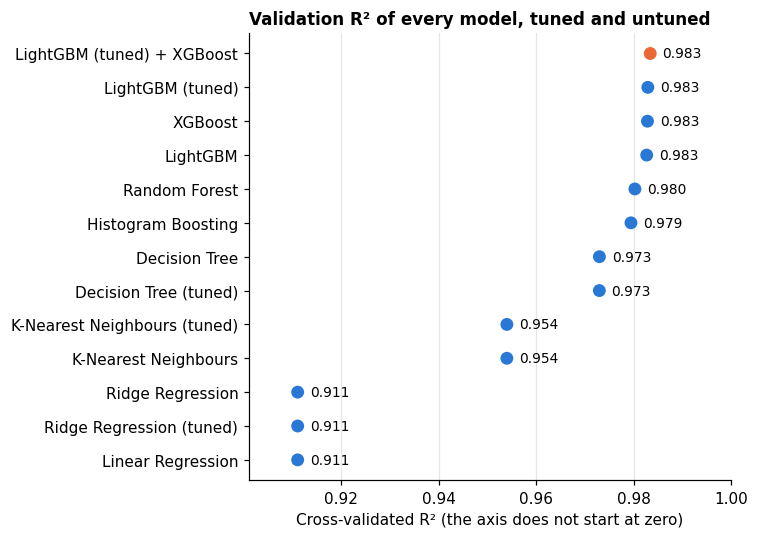

In [36]:
final_comparison = pd.DataFrame(results).set_index('model').sort_values('R2', ascending=False)
display(final_comparison[['R2', 'RMSE', 'MAE']].round({'R2': 4, 'RMSE': 0, 'MAE': 0}))

shown = final_comparison.drop(index='Mean price (baseline)').sort_values('R2')
fig, ax = plt.subplots(figsize=(7, 5))
colours = [BUSINESS if '+' in name else ECONOMY for name in shown.index]
ax.scatter(shown['R2'], shown.index, s=55, color=colours, zorder=3)
for position, value in enumerate(shown['R2']):
    ax.annotate(f'{value:.3f}', (value, position), xytext=(8, 0), textcoords='offset points', va='center', fontsize=9)
ax.set_xlim(shown['R2'].min() - 0.01, 1.0)
ax.set_xlabel('Cross-validated R² (the axis does not start at zero)')
ax.set_title('Validation R² of every model, tuned and untuned')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Tuning confirmed the starting settings rather than improving on them.** For Ridge and KNN, the grid search picked exactly the settings the models started with: alpha = 1, and 10 neighbours with closer tickets counting more. For the Decision Tree it chose a depth limit of 20 with the same minimum of 5 tickets per leaf, which scores the same.

The searches still show what matters. Ridge barely reacts to alpha, because with almost 40,000 rows and few columns there is little overfitting to correct. KNN does clearly better when closer tickets count more (0.951 against 0.941 for the best equal-weight setting in 3-fold CV). LightGBM's best and worst combinations are only about 0.001 apart, and tuning adds 0.0002. The models are limited by the information in the data more than by their settings.

Averaging tuned LightGBM with XGBoost helps more than tuning did. The two models make somewhat different mistakes, so averaging cancels part of the error. This adds little complexity and uses models already built, so **this blend is the final model**.

## 10. Where the final model goes wrong

The out-of-fold predictions are used here, since no model saw these rows during training.

Overall R2: 0.9834



,R2 within class,RMSE,MAE,MAE as % of median price
class,,,,
Economy,0.734,1890.0,1115.0,19.7
Business,0.884,4436.0,2537.0,4.8


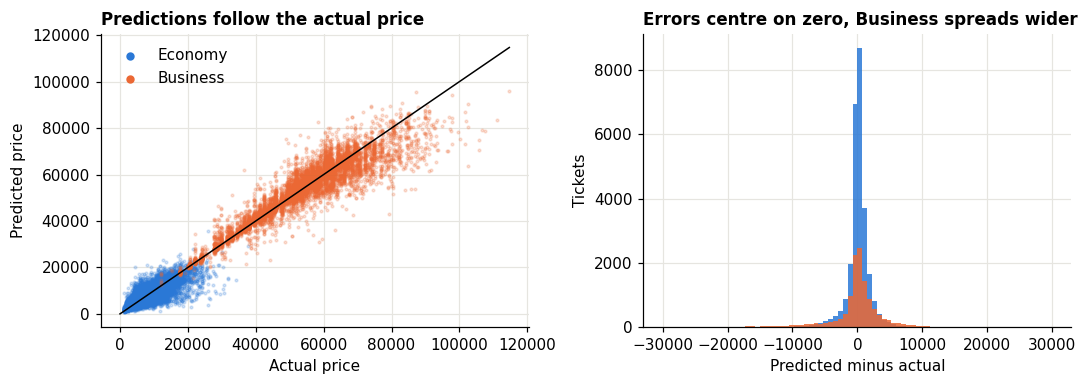

In [37]:
final_oof = out_of_fold['LightGBM (tuned) + XGBoost']
review = train.assign(predicted=final_oof, error=final_oof - y, airline=repair_flight_codes(train)['airline'])

print(f'Overall R2: {r2_score(y, final_oof):.4f}\n')
summary = []
for cls in ['Economy', 'Business']:
    part = review[review['class'] == cls]
    summary.append({'class': cls, 'R2 within class': r2_score(part['price'], part['predicted']),
                    'RMSE': np.sqrt(mean_squared_error(part['price'], part['predicted'])),
                    'MAE': mean_absolute_error(part['price'], part['predicted']),
                    'MAE as % of median price': 100 * mean_absolute_error(part['price'], part['predicted']) / part['price'].median()})
display(pd.DataFrame(summary).set_index('class').round({'R2 within class': 3, 'RMSE': 0, 'MAE': 0, 'MAE as % of median price': 1}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for cls, colour in CLASS_COLOURS.items():
    part = review[review['class'] == cls]
    axes[0].scatter(part['price'], part['predicted'], s=3, alpha=0.2, color=colour)
    axes[0].scatter([], [], s=20, color=colour, label=cls)
limit = review['price'].max()
axes[0].plot([0, limit], [0, limit], color='black', linewidth=1)
axes[0].set(title='Predictions follow the actual price', xlabel='Actual price', ylabel='Predicted price')
axes[0].legend()
for cls, colour in CLASS_COLOURS.items():
    axes[1].hist(review.loc[review['class'] == cls, 'error'], bins=80, range=(-30000, 30000), color=colour, alpha=0.85)
axes[1].set(title='Errors centre on zero, Business spreads wider', xlabel='Predicted minus actual', ylabel='Tickets')
plt.tight_layout()
plt.show()

**Insight: the overall R² flatters the model.** A large part of the 0.98 comes from separating Economy and Business, which is easy. Inside each class the score is noticeably lower, at about 0.73 for Economy and 0.88 for Business. That is the fairer measure of how well the model prices an individual ticket.

Business has the larger errors in absolute terms, and these dominate RMSE. Economy has the larger errors relative to its price: the average miss is about 20% of a typical Economy fare, against about 5% for Business. Some of this variation probably comes from things the data does not include, such as seats remaining or the exact travel date.

## 11. What drives the price

Permutation importance measures how much the score drops when one column is shuffled. A big drop means the model relies on that column. It is computed on rows held out from training, for tuned LightGBM, which is half of the blend.

The score is also computed inside each class, because the overall R² is dominated by the gap between classes.

,All tickets,Economy only,Business only
class,1.566,0.000,0.000
flight,0.101,0.211,0.745
duration,0.082,0.120,0.630
destination,0.022,0.075,0.196
days_left,0.022,0.868,0.061
stops,0.017,0.059,0.109
airline,0.009,0.178,0.023
source,0.003,0.030,0.027
arrival,0.002,0.007,0.018
departure,0.000,0.002,0.002


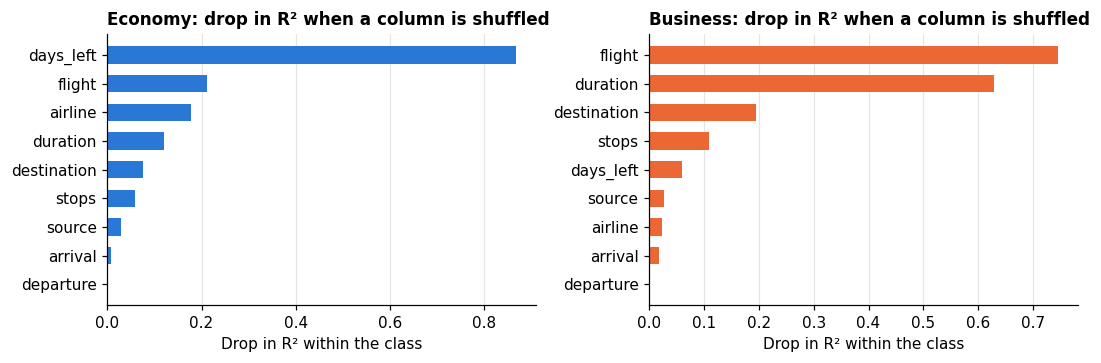

In [38]:
fit_part, holdout_part, y_fit, y_holdout = train_test_split(X, y, test_size=0.2, random_state=SEED)
importance_model = boosting_pipeline(LGBMRegressor(**TUNED_PARAMS)).fit(fit_part, y_fit)

def importance_for(rows):
    result = permutation_importance(importance_model, holdout_part[rows], y_holdout[rows],
                                    n_repeats=3, random_state=SEED, scoring='r2')
    return pd.Series(result.importances_mean, index=holdout_part.columns)

is_economy = (holdout_part['class'] == 'Economy').values
importance = pd.DataFrame({
    'All tickets': importance_for(np.ones(len(holdout_part), dtype=bool)),
    'Economy only': importance_for(is_economy),
    'Business only': importance_for(~is_economy),
}).sort_values('All tickets', ascending=False)
display(importance.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, cls, column in zip(axes, ['Economy', 'Business'], ['Economy only', 'Business only']):
    values = importance[column].drop('class').sort_values()
    ax.barh(values.index, values.values, color=CLASS_COLOURS[cls], height=0.6)
    ax.set_title(f'{cls}: drop in R² when a column is shuffled')
    ax.set_xlabel('Drop in R² within the class')
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Insight: the main drivers are different in each class.** Across all tickets, `class` dominates. Shuffling it drops R² by more than 1, which means predictions become worse than guessing the average.

The "All tickets" column makes `days_left` look minor, but that is misleading, because the overall score is dominated by the gap between classes and by expensive Business fares. Inside each class the picture changes:

- **Economy** depends mainly on `days_left`, followed by `flight` and `airline`. This is timing-based pricing.
- **Business** depends mainly on `flight` and `duration`, and `days_left` matters little.

`departure` adds almost nothing, probably because the flight code already implies the departure time.

## 12. Training the final model and writing `submission.csv`

Both models are refitted on all training rows, since cross-validation has already given the performance estimate. Their test predictions are then averaged.

In [39]:
final_lightgbm = boosting_pipeline(LGBMRegressor(**TUNED_PARAMS)).fit(X, y)
final_xgboost = boosting_pipeline(XGBRegressor(**XGB_PARAMS)).fit(X, y)

test_predictions = (final_lightgbm.predict(X_test) + final_xgboost.predict(X_test)) / 2
test_predictions = np.clip(test_predictions, train['price'].min(), None)

submission = pd.DataFrame({'id': test['id'], 'price': test_predictions})
submission.to_csv('submission.csv', index=False)

assert submission.shape == (len(test), 2)
assert submission['id'].is_unique and submission['price'].notna().all()
sample_path = find_file('sample_submission.csv')
if os.path.exists(sample_path):
    sample = pd.read_csv(sample_path)
    assert list(sample.columns) == list(submission.columns) and (sample['id'] == submission['id']).all()
    print('Format matches the sample submission')

print(submission['price'].describe().round(0).to_string())
print('\nTraining price mean:', round(train['price'].mean()), '  Test prediction mean:', round(submission['price'].mean()))
submission.head()

Format matches the sample submission
count    10000.0
mean     20852.0
std      22528.0
min       1105.0
25%       4972.0
50%       7478.0
75%      43223.0
max      92924.0

Training price mean: 20752   Test prediction mean: 20852


,id,price
0,0,3979.082391
1,1,8550.342450
2,2,5126.835578
3,3,58082.403817
4,4,48940.923072


## 13. Conclusions

**Final model.** The final prediction is the average of tuned LightGBM and XGBoost, trained on all 39,750 rows left after removing duplicates. Its cross-validated R² is about 0.983, with RMSE about 2,900 and MAE about 1,600. The baseline of always predicting the average has an R² of about 0.

**What the data showed**

1. `class` splits the market in two. A typical Business ticket costs about nine times a typical Economy ticket.
2. Economy pricing is about timing. Fares jump sharply about two weeks before departure and keep rising.
3. Business pricing is about the specific flight and its duration, and depends far less on when the ticket is booked.
4. Non-stop flights are the cheapest in both classes, and routes out of Kolkata are the most expensive in Economy.

**What improved the model most**

1. Moving from linear models to tree ensembles took R² from about 0.91 to about 0.98.
2. Using the flight code took LightGBM's R² from about 0.971 to about 0.981.
3. Finding the damaged Indigo codes recovered every missing airline with no guessing, and filling schedule gaps from each flight's usual schedule was far more accurate than using overall averages.
4. Hyperparameter tuning on four models made almost no difference: the grid searches confirmed the starting settings, and LightGBM gained only 0.0002. Blending two models added slightly more.

**Limits**

- The overall R² is flattered by the easy split between classes. Within class it is about 0.73 for Economy and 0.88 for Business.
- Most Indigo flight numbers are lost, so individual Indigo flights cannot be told apart.
- The data has no seat availability or exact travel date, which probably explains part of the remaining error.